In [2]:
import pandas as pd
df = pd.read_csv("data/fig2_source_data.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(2098, 6)
['Unnamed: 0', 'HUC8', 'Fig2a_WetlandDensity', 'Fig2b_PercentNRemoval', 'Fig2c_NSurplus', 'Fig2d_EstNRemoval']


,Unnamed: 0,HUC8,Fig2a_WetlandDensity,Fig2b_PercentNRemoval,Fig2c_NSurplus,Fig2d_EstNRemoval
0,1,1010002,0.058591,0.246729,1.623849,0.198939
1,2,1010003,0.090101,0.337604,4.365647,0.721574
2,3,1010004,0.108125,0.369333,8.175619,1.477887
3,4,1010005,0.142440,0.412268,7.970005,1.624673
4,5,1010006,0.109113,0.372959,1.598004,0.300307


In [5]:
df = pd.read_csv("data/fig2_source_data.csv")  
df = df.drop(columns=["Unnamed: 0"])
df = df.rename(columns={
    "Fig2a_WetlandDensity": "wetland_density",
    "Fig2b_PercentNRemoval": "pct_n_removal",
    "Fig2c_NSurplus": "n_surplus",
    "Fig2d_EstNRemoval": "est_n_removal",
})
df["region"] = df["HUC8"] // 1_000_000

print(df.isna().sum())
df.describe()

HUC8               0
wetland_density    0
pct_n_removal      0
n_surplus          0
est_n_removal      0
region             0
dtype: int64


,HUC8,wetland_density,pct_n_removal,n_surplus,est_n_removal,region
count,2.098000e+03,2098.000000,2098.000000,2098.000000,2098.000000,2098.000000
mean,9.897083e+06,0.071984,0.198496,14.253679,1.483597,9.819828
std,5.114868e+06,0.099732,0.147624,16.652882,2.039449,5.123459
min,1.010002e+06,0.000006,0.000026,-2.022984,0.000000,1.000000
25%,5.100204e+06,0.018535,0.078413,2.753061,0.136304,5.000000
50%,1.017015e+07,0.030948,0.132619,8.173884,0.650430,10.000000
75%,1.406001e+07,0.083866,0.319653,19.902572,2.039524,14.000000
max,1.810020e+07,1.000000,0.525841,177.080645,20.329702,18.000000


In [6]:
quant = ["wetland_density", "pct_n_removal", "n_surplus", "est_n_removal"]

summary = df[quant].agg(["mean", "median", "std"]).T
summary["skew"] = df[quant].skew()
summary = summary.round(3)
summary

,mean,median,std,skew
wetland_density,0.072,0.031,0.100,3.373
pct_n_removal,0.198,0.133,0.148,0.758
n_surplus,14.254,8.174,16.653,2.546
est_n_removal,1.484,0.650,2.039,2.623


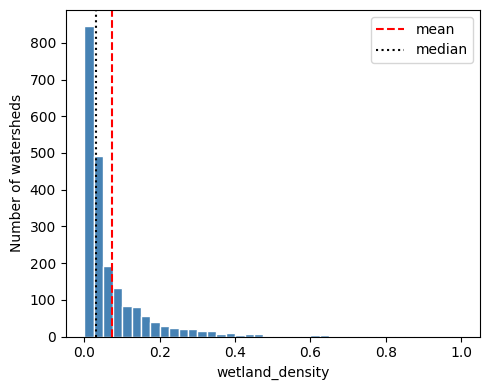

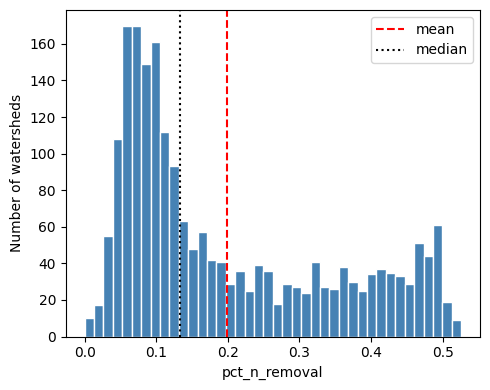

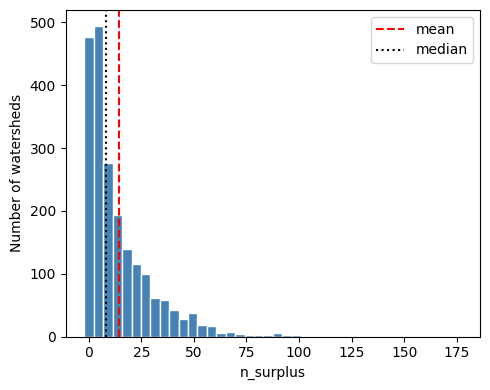

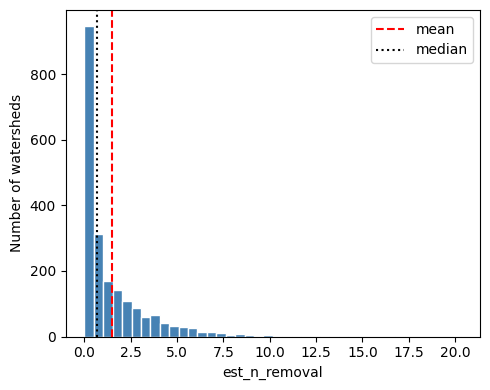

In [7]:
import matplotlib.pyplot as plt

for col in quant:
    plt.figure(figsize=(5, 4))
    plt.hist(df[col], bins=40, color="steelblue", edgecolor="white")
    plt.axvline(df[col].mean(), color="red", ls="--", label="mean")
    plt.axvline(df[col].median(), color="black", ls=":", label="median")
    plt.xlabel(col)
    plt.ylabel("Number of watersheds")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"figures/hist_{col}.png", dpi=300)
    plt.show()

In [8]:
df.nlargest(10, "wetland_density")[["HUC8", "region", "wetland_density", "n_surplus"]]

,HUC8,region,wetland_density,n_surplus
767,8030100,8,1.000000,16.337446
796,8060100,8,0.869142,10.367452
803,8070100,8,0.866740,7.251167
351,4010201,4,0.832420,2.591136
866,9030007,9,0.755587,1.509354
810,8080101,8,0.715592,10.631994
756,8020100,8,0.641914,22.448434
286,3130013,3,0.637723,2.303292
218,3060109,3,0.632929,4.551304
246,3090202,3,0.614319,12.306259


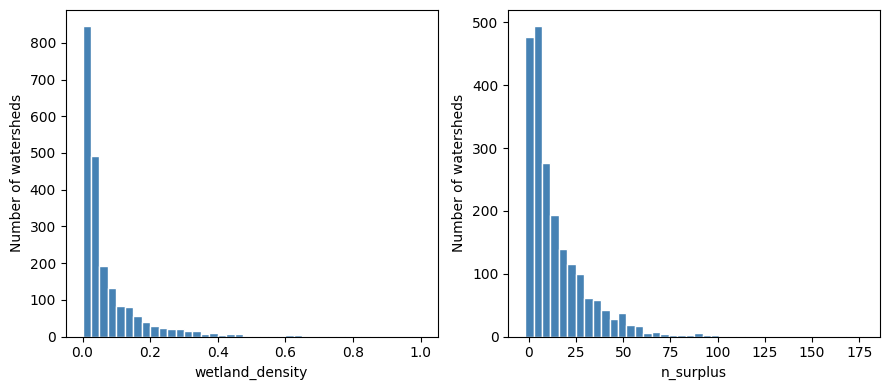

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col in zip(axes, ["wetland_density", "n_surplus"]):
    ax.hist(df[col], bins=40, color="steelblue", edgecolor="white")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of watersheds")
plt.tight_layout()
plt.savefig("figures/fig1_histograms.png", dpi=300)
plt.show()